# Market Risk Analysis: Single-Asset Diagnostics

## Objective and scope

This notebook uses Apple (AAPL) price data to demonstrate a small set of foundational market-risk calculations. It moves from price data to returns, examines return variability and serial dependence, measures drawdown, and estimates one-day Value at Risk (VaR) using historical and parametric approaches.

The notebook is intentionally a **single-asset introduction**, not yet a complete portfolio-risk engine. Its measures are useful building blocks, but they do not by themselves describe a diversified portfolio or establish how a risk model performs out of sample.

### Workflow

1. Retrieve adjusted daily prices and calculate daily and month-end returns.
2. Compare sample and population variance estimates.
3. Inspect autocorrelation in daily returns with ACF and PACF.
4. Calculate and visualize drawdowns.
5. Estimate historical-simulation VaR and rolling normal-parametric VaR.

**Interpretation convention:** returns are stored as decimals (for example, `0.01` represents 1%). VaR is discussed as a one-day, 95% confidence measure unless otherwise stated.


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

### Libraries

- `pandas` and `numpy` support tabular data and numerical calculations.
- `matplotlib` produces the diagnostic charts.
- `yfinance` retrieves market price history.

The time-series diagnostics, normal quantile, and date-axis formatting libraries are imported in the cells where they are first needed.


## 1. Retrieve adjusted closing prices

The analysis uses AAPL daily observations over the date range defined below. The `Adj Close` series adjusts historical prices for distributions and corporate actions, making it more appropriate than an unadjusted close for return calculations. `auto_adjust=False` is specified so that the returned data retains the separate `Adj Close` field.

The download result is selected as a one-column pandas object. Depending on the `yfinance` version, that one-column result can still be a DataFrame rather than a Series; the downstream cells therefore use two-dimensional indexing in a few places.


In [40]:
ticker = 'AAPL'
start_date = '2023-12-28'
end_date = '2024-12-01'

stock_data = yf.download(tickers=ticker, start= start_date, end= end_date, interval='1d', auto_adjust=False)['Adj Close']
stock_data.head()

[*********************100%***********************]  1 of 1 completed


Ticker,AAPL
Date,
2023-12-28,191.248398
2023-12-29,190.210999
2024-01-02,183.404007
2024-01-03,182.030746
2024-01-04,179.718933


### Price-data check

The displayed rows provide a quick check that the download returned dated observations and adjusted prices. The chosen end date bounds the period requested from the data provider; the latest available trading observation can fall before that calendar date. All following calculations are conditional on the downloaded sample being correct and sufficiently representative for the intended illustration.


## 2. Calculate daily simple returns

For each trading day, the simple return is

\[ r_t = \frac{P_t}{P_{t-1}} - 1, \]

where \(P_t\) is the adjusted closing price. `pct_change()` calculates this percentage change, and `dropna()` removes the first observation because it has no preceding price in the downloaded sample. These daily returns are the main input for the time-series diagnostics and daily VaR calculations below.


In [41]:
daily_returns = stock_data.pct_change().dropna()
daily_returns

Ticker,AAPL
Date,
2023-12-29,-0.005424
2024-01-02,-0.035787
2024-01-03,-0.007488
2024-01-04,-0.012700
2024-01-05,-0.004013
...,...
2024-11-22,0.005908
2024-11-25,0.013051
2024-11-26,0.009404


### Daily-return check

The output contains 232 daily return observations in the saved notebook output. Individual values are decimal returns: negative values indicate a decrease from the previous observed adjusted close, while positive values indicate an increase. A single large daily move can materially affect empirical quantiles and volatility estimates, so the distribution should be inspected before relying on a risk number.


## 3. Convert prices to month-end returns

The next calculation resamples the daily adjusted prices to month-end observations. `ffill()` carries the latest available trading price to the calendar month-end when that date is not a trading day; `pct_change()` then calculates the return from one month-end price to the next. The first return is dropped because it has no previous month-end observation within the resampled series.

Monthly returns are used here for the variance comparison, while daily returns are retained for autocorrelation, drawdown, and one-day VaR. The two frequencies should not be mixed when interpreting a variance or risk estimate.


In [45]:
monthly_returns = stock_data.resample('ME').ffill().pct_change().dropna()
monthly_returns 

Ticker,AAPL
Date,
2024-01-31,-0.042227
2024-02-29,-0.018543
2024-03-31,-0.051286
2024-04-30,-0.006706
2024-05-31,0.130222
2024-06-30,0.095553
2024-07-31,0.054411
2024-08-31,0.032353
2024-09-30,0.017467


### Monthly-return check

The saved output shows 11 month-end returns from January through November 2024. These summarize price changes between successive month-end observations and are coarser than the daily series. Because the requested data window ends at the start of December 2024, the notebook does not contain a December month-end return.


## 4. Compare sample and population variance

Variance measures the dispersion of returns around their mean. Pandas uses `ddof=1` for the sample variance, dividing the sum of squared deviations by \(n-1\), and `ddof=0` for the population-style calculation, dividing by \(n\). For the same finite sample, the former is larger.

These values are calculated from **monthly returns**, so the resulting variances are in squared-return units. The sample estimate is commonly used when estimating an underlying return distribution from observed data; the population-style figure is the variance of the observed sample under the divisor-n convention.


In [43]:
sample_variance = monthly_returns.var(ddof=1)
population_variance = monthly_returns.var(ddof=0)

print(f"Sample Variance (Unbiased estimator): {sample_variance.iloc[0]:.6f}")
print(f"Population Variance (Biased estimator): {population_variance.iloc[0]:.6f}")

Sample Variance (Unbiased estimator): 0.003389
Population Variance (Biased estimator): 0.003081


In [44]:
sample_variance.values

array([0.00338872])

### Interpretation

The sample variance is approximately `0.003389`, compared with approximately `0.003081` for the population-style calculation. This difference follows from the two divisor choices, not from different input data. The `sample_variance.values` cell simply displays the same estimate as a NumPy array; it does not introduce a new calculation or a new risk measure.


## 5. Examine serial dependence in daily returns

The **autocorrelation function (ACF)** measures the correlation between returns and lagged values of the same series. The **partial autocorrelation function (PACF)** estimates the relationship at a given lag after accounting for shorter lags. Here, both are evaluated on the raw daily-return series for lags up to 30 trading observations.

The shaded confidence bands provide a visual reference for whether an estimated correlation differs from zero under the plotting assumptions. These charts are exploratory diagnostics; they are not a complete statistical test of market efficiency or of the absence of dependence.


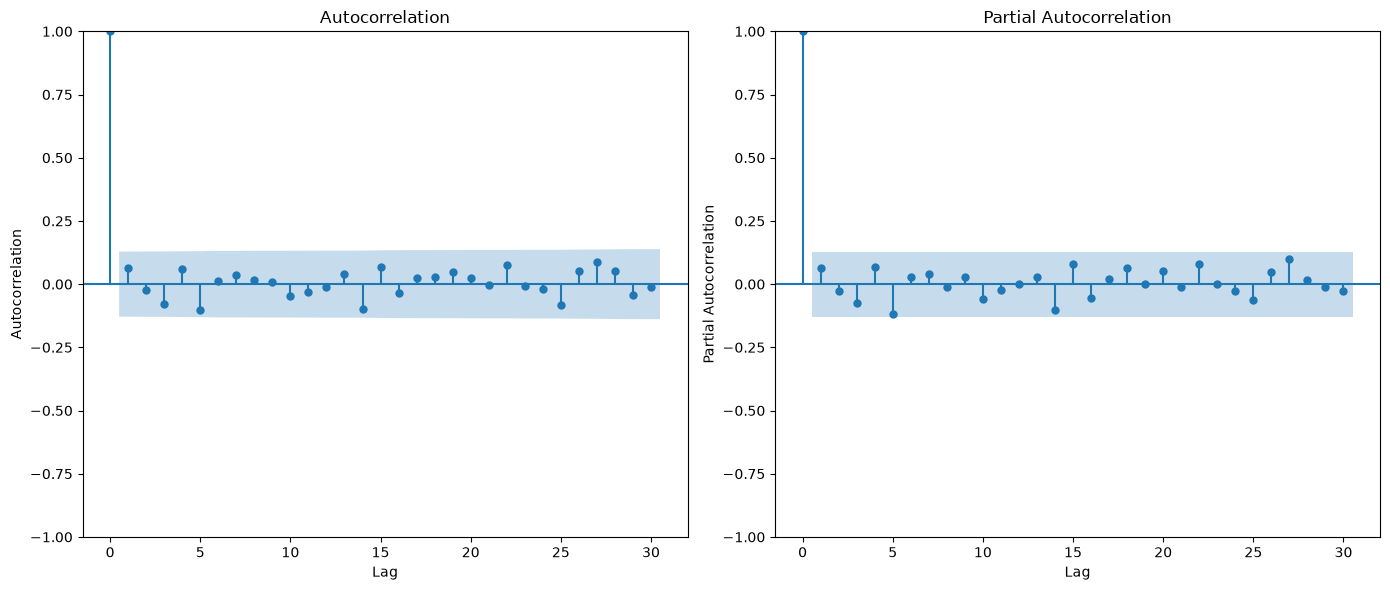

In [46]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf

fig, axes = plt.subplots(1,2, figsize = (14,6))

plot_acf(daily_returns, lags=30, alpha= 0.05, ax= axes[0])
axes[0].set_xlabel('Lag')
axes[0].set_ylabel("Autocorrelation")

plot_pacf(daily_returns, lags=30, alpha= 0.05, ax=axes[1])
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('Partial Autocorrelation')

plt.tight_layout()
plt.show()

In [48]:
autocorr_coeffs = acf(daily_returns, nlags = 30, fft = False)
print(f"Autoorrelation Coefficients (30 Lags): \n {autocorr_coeffs}")

Autoorrelation Coefficients (30 Lags): 
 [ 1.          0.06352626 -0.0243964  -0.07832034  0.05951812 -0.10288377
  0.01332575  0.03712484  0.01768074  0.00796392 -0.04747106 -0.03239021
 -0.01064995  0.04126751 -0.09813702  0.06820049 -0.03675446  0.02623427
  0.02769311  0.0472426   0.02346703 -0.00154563  0.07621389 -0.00550008
 -0.01973465 -0.08078781  0.05075338  0.08787846  0.0539117  -0.04287522
 -0.01062522]


### Reading the ACF/PACF output

The printed ACF array includes lag 0, which is 1 by definition; the subsequent entries correspond to lags 1 through 30. In this sample, the reported raw-return autocorrelations at nonzero lags are generally small, with magnitudes around 0.1 or less. The charts and coefficients do not show strong linear serial correlation in raw daily returns, but that observation alone does **not** imply that returns are independent or that volatility is constant. To investigate volatility clustering, one would typically also inspect absolute or squared returns and/or fit a volatility model.


## 6. Calculate maximum drawdown

The first calculation compounds the sequence of daily returns into a wealth index,

$$W_t = \prod_{i=1}^{t}(1+r_i),$$

then tracks the running peak $M_t = \max_{s \le t} W_s$. Drawdown is the percentage decline from that running peak, $D_t=(W_t-M_t)/M_t$. It is zero at a running high and negative below a previous high. Maximum drawdown is the most negative observed value in the series.

The wealth index begins with the first available return in this sample; there is no separate initial row with a value of 1.0. This scaling does not change the drawdown ratios.

In [50]:
cumulative_returns = (1 + daily_returns).cumprod()
running_max = cumulative_returns.cummax()

drawdown = (cumulative_returns - running_max) / running_max

max_drawdown = drawdown.min() * 100

print(f"Maximum Drawdown: {max_drawdown.iloc[0]:.2f}")

Maximum Drawdown: -15.35


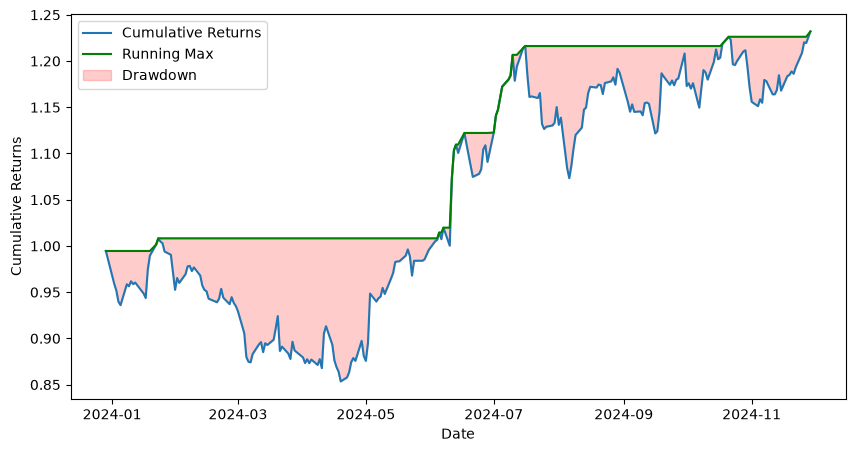

In [70]:
plt.figure(figsize=(10,5))
plt.plot(cumulative_returns, label = "Cumulative Returns")
plt.plot(running_max, label = "Running Max", color = "Green")
plt.fill_between(cumulative_returns.index, cumulative_returns.iloc[:,0].to_numpy(), running_max.iloc[:,0].to_numpy(), color = "Red", alpha = 0.2, label = "Drawdown")
plt.xlabel("Date")
plt.ylabel("Cumulative Returns")
plt.legend()
plt.show()

[]

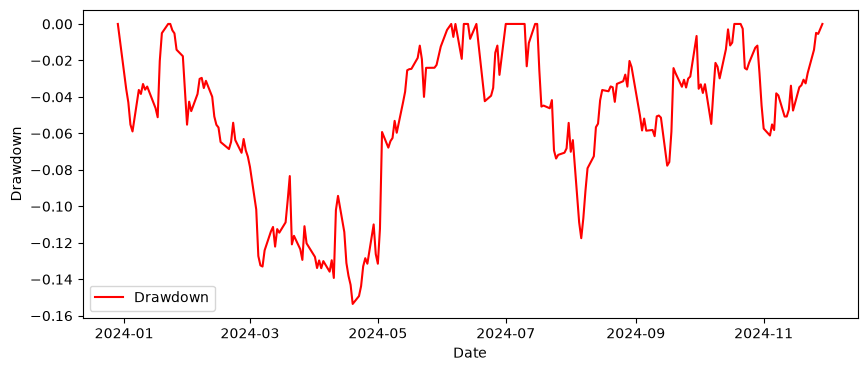

In [58]:
plt.figure(figsize=(10,4))
plt.plot(
    drawdown,
    label = "Drawdown",
    color = "Red"
)

plt.legend()
plt.xlabel("Date")
plt.ylabel("Drawdown")


plt.plot()

### Reading the drawdown results

The saved calculation reports a maximum drawdown of approximately **-15.35%** over the observed return path. The negative sign is intentional: drawdown represents a decline from a previous running high. The first plot shows the wealth index against its running maximum and shades the gap; the second isolates the drawdown series so the depth and duration of declines are easier to inspect. This is a historical peak-to-trough measure, not a forecast of the next loss.


### Diagnostic: inspect the cumulative-return array shape

This cell is a shape check rather than a risk calculation. A result of `(232, 1)` indicates 232 daily observations and one AAPL column. It also confirms that `cumulative_returns` remains two-dimensional because the selected price data has been retained as a one-column DataFrame.


In [67]:
cumulative_returns.to_numpy().shape

(232, 1)

The shape output is `(232, 1)`, consistent with the daily-return DataFrame shape. This check is useful when troubleshooting pandas operations, but it does not contribute directly to the risk interpretation.


## 7. Historical-simulation VaR

Historical-simulation VaR uses the empirical distribution of observed daily returns rather than imposing a normal distribution. The 95% VaR cutoff is obtained from the 5th percentile of daily returns, i.e. the return threshold below which approximately 5% of observations in this sample fall. The histogram visualizes this empirical distribution and marks that threshold.

**Sign convention:** `var_95` stores the 5th-percentile **return**, so it will typically be negative. It is not converted into a positive dollar-loss amount in this cell. This is a one-day estimate based on the historical AAPL sample; it is not a guarantee about future losses.


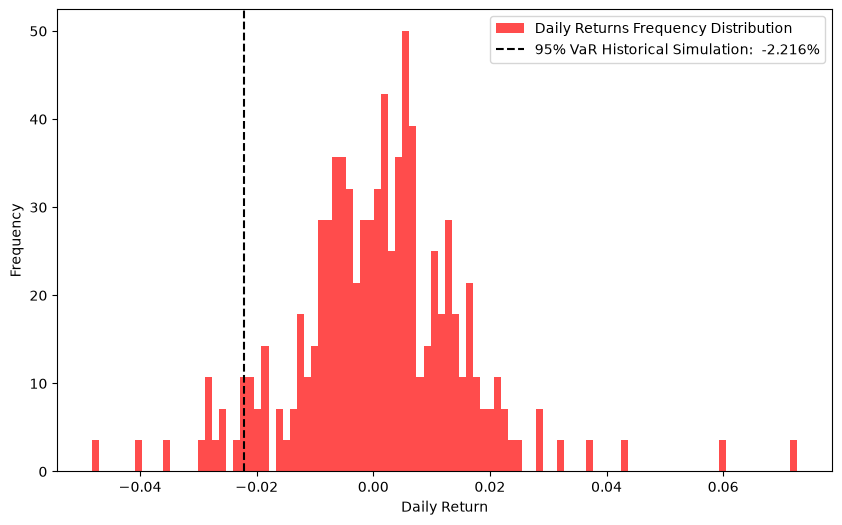

In [74]:
var_95 = daily_returns.quantile(0.05).iloc[0]

plt.figure(figsize=(10,6))
plt.hist(daily_returns, bins=100, density=True, color="Red", alpha = 0.7, label = "Daily Returns Frequency Distribution")
plt.axvline(daily_returns.quantile(0.05).iloc[0], color = "Black", linestyle = '--', label = f"95% VaR Historical Simulation:  {var_95:.3%}")
plt.legend()
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

### Interpretation and limitation

The vertical line identifies the historical 5th-percentile daily return. Under the empirical sample, around 5% of observations are at or below the cutoff and around 95% are above it. With only about 232 daily observations, this tail estimate is based on a relatively small number of observations and can be sensitive to the chosen time window. The measure also assumes the historical sample is informative about the distribution relevant to the risk horizon.


## 8. Rolling normal-parametric VaR

This final calculation estimates a time-varying one-day VaR from a rolling window of 100 daily returns. For each eligible date, it estimates the rolling mean \(\mu_t\) and standard deviation \(\sigma_t\), then uses the 95th percentile of the standard normal distribution, \(z_{0.95}\), to form the lower-tail return threshold \(\mu_t-z_{0.95}\sigma_t\). The result is multiplied by the assumed portfolio value and negated to express the threshold as a dollar loss amount:

\[ \operatorname{VaR}_{0.95,t}=-P_0(\mu_t-z_{0.95}\sigma_t). \]

The plot compares this rolling VaR estimate with the daily dollar P&L proxy, computed as the negative of return times `P0`. The first 99 observations have no rolling estimate because the code requires a complete 100-observation window.

**Model assumptions and scope:** this is a normal-parametric estimate, so it relies on the rolling mean and standard deviation summarizing the relevant tail of the return distribution. `P0` is fixed at $1,000,000, and AAPL's returns are used as the portfolio-return proxy. This is therefore an illustrative constant-exposure scaling, not a valuation of an actual share portfolio or a diversified portfolio.


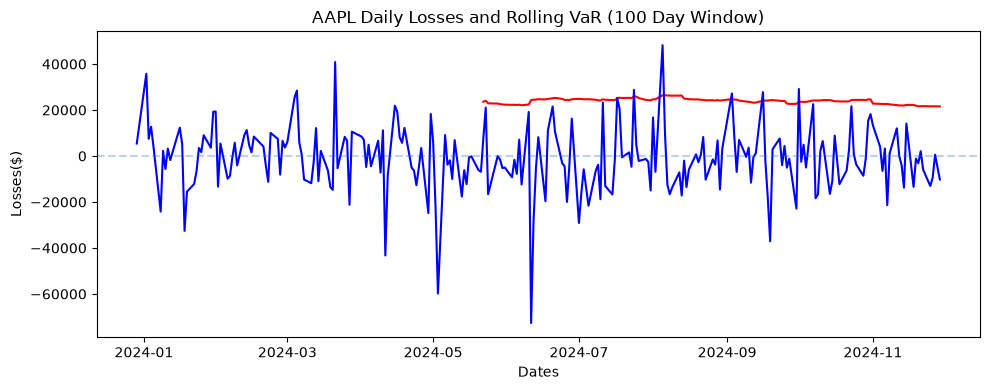

In [78]:
from scipy.stats import norm
import matplotlib.dates as mdates

window_size = 100 

mu_rolling = daily_returns.rolling(window=window_size, min_periods=window_size).mean()
sigma_rolling = daily_returns.rolling(window=window_size, min_periods=window_size).std()
z_score = norm.ppf(0.95)

P0 = 1_000_000
rolling_var = - P0 * (mu_rolling - z_score * sigma_rolling)
daily_losses = - P0 * daily_returns

plt.figure(figsize=(10,4))

plt.plot(rolling_var, color = "Red", label = "Rolling 95% VaR ($)")
plt.plot(daily_losses, color = "Blue", label = "Daily Portfolio Losses ($)")
plt.axhline(0, linestyle = "--", alpha = .3)

plt.title(f"{ticker} Daily Losses and Rolling VaR ({window_size} Day Window)")
plt.xlabel("Dates")
plt.ylabel("Losses($)")
plt.tight_layout()
plt.show()

### How to interpret the comparison

The red line is the rolling parametric 95% VaR in dollars; the blue line is the daily dollar-loss proxy. Values of the blue series below zero correspond to positive returns (profits) under the chosen sign convention, while positive values correspond to losses. A VaR exceedance occurs when the realized loss is larger than the estimated VaR for that date; a visual comparison is helpful, but formal backtesting would be needed to assess model calibration.

## Summary and next steps

This notebook establishes a useful first layer of market-risk analysis: return construction, variance, dependence diagnostics, drawdown, and two different one-day VaR approaches. Its simplicity is appropriate for a foundational notebook, but it should be presented as **single-asset exploratory analysis** rather than as a finished risk engine.

To extend it into a broader portfolio market-risk project, natural additions would include a multi-asset portfolio with explicit weights and rebalancing, covariance/correlation and volatility modeling, Expected Shortfall, portfolio risk attribution, stress scenarios, and VaR backtesting. These are extensions rather than calculations performed in this notebook.
